In [5]:
import numpy as np
import os
import energycal
from tqdm import tqdm

In [3]:
path = 'data/testcoinc.bin'
row_size = 16
num_rows = os.path.getsize(path) // row_size
dtypes = np.dtype([('time', np.int64), 
                    ('energy', np.float32), 
                    ('id', np.int32)])
data = np.memmap(path, dtype=dtypes, mode='r', shape=(num_rows,))
print(data[0:3])
print(num_rows)
photopeaks = np.fromfile('photopeaks.bin')
escalars = energycal.obtainscalars(photopeaks)


[(6471509218573, 21.53748  , 53) (6471509219847,  6.9428177, 63)
 (6471509219762,  4.1113434, 45)]
54415706


In [16]:
leakagematrix = np.zeros((64, 64)) # Models leakage from crystal at row -> col
leakagecounts = np.zeros((64, 64))
for i in tqdm(range(0, num_rows, 1000000)):
    chunk = np.array(data[i:i+1000000])
    chunk = chunk[chunk['id'] > 127]
    chunk = chunk[chunk['id'] < 192]
    chunk['energy'] = energycal.convertenergy(chunk['energy'], escalars[chunk['id']])
    chunk['id'] = chunk['id'] % 64
    lasttime = chunk[0]['time']
    sidx, eidx = 0, 0
    neventsthisgroup = 0
    for i in range(len(chunk)):
        if chunk[i]['time'] - lasttime > 10000:
            if np.any(np.isclose(chunk[sidx:eidx]['energy'], 511.0, atol = 20.0)):
                centralid = chunk[sidx:eidx]['id'][np.where(np.isclose(chunk[sidx:eidx]['energy'], 511.0, atol = 20.0))[0][0]]
                leakagematrix[centralid, chunk[sidx:eidx]['id']] += chunk[sidx:eidx]['energy']
                leakagecounts[centralid, chunk[sidx:eidx]['id']] += 1
            sidx = eidx
            lasttime = chunk[i]['time']
            neventsthisgroup = 0
        eidx += 1
        neventsthisgroup += 1
leakagematrix = leakagematrix / leakagecounts
for i in range(64): # Normalize by central crystal
    leakagematrix[:, i] = leakagematrix[:, i] / leakagematrix[i, i]
leakagematrix[np.isnan(leakagematrix)] = 0

100%|██████████| 55/55 [00:32<00:00,  1.67it/s]
/tmp/ipykernel_255058/1846802389.py:23: RuntimeWarning: invalid value encountered in divide
  leakagematrix = leakagematrix / leakagecounts


In [18]:
leakagematrix = leakagematrix.astype(np.float32)
leakagematrix.tofile('leakagematrix.bin')

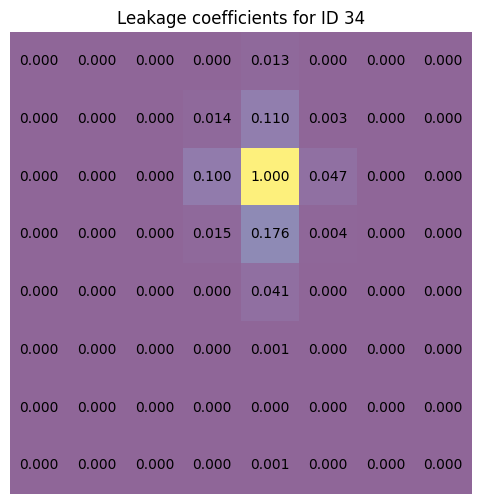

In [34]:
def plotleakagematrixrow(id):
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches
    indices = {
        0: (4, 0),
        1: (4, 1),
        2: (7, 2),
        3: (5, 0),
        4: (5, 3),
        5: (5, 2),
        6: (4, 3),
        7: (7, 0),
        8: (6, 1),
        9: (7, 3),
        10: (5, 1),
        11: (6, 3),
        12: (4, 2),
        13: (6, 2),
        14: (6, 0),
        15: (7, 1),
        16: (3, 0),
        17: (3, 1),
        18: (2, 0),
        19: (2, 1),
        20: (0, 0),
        21: (1, 0),
        22: (0, 1),
        23: (1, 1),
        24: (3, 2),
        25: (1, 2),
        26: (2, 2),
        27: (4, 4),
        28: (0, 2),
        29: (3, 3),
        30: (0, 3),
        31: (1, 3),
        32: (2, 3),
        33: (3, 4),
        34: (2, 4),
        35: (0, 4),
        36: (1, 4),
        37: (0, 5),
        38: (5, 4),
        39: (1, 5),
        40: (2, 5),
        41: (3, 5),
        42: (1, 6),
        43: (0, 6),
        44: (0, 7),
        45: (3, 6),
        46: (1, 7),
        47: (2, 6),
        48: (3, 7),
        49: (2, 7),
        50: (6, 5),
        51: (6, 6),
        52: (7, 6),
        53: (4, 6),
        54: (5, 6),
        55: (6, 7),
        56: (7, 7),
        57: (7, 5),
        58: (7, 4),
        59: (4, 5),
        60: (5, 7),
        61: (5, 5),
        62: (6, 4),
        63: (4, 7),
        64: (11, 7),
        65: (11, 6),
        66: (10, 4),
        67: (10, 6),
        68: (11, 4),
        69: (9, 7),
        70: (9, 5),
        71: (8, 7),
        72: (9, 6),
        73: (11, 3),
        74: (10, 7),
        75: (10, 3),
        76: (11, 5),
        77: (8, 5),
        78: (10, 5),
        79: (8, 6),
        80: (12, 7),
        81: (14, 7),
        82: (13, 7),
        83: (15, 7),
        84: (13, 6),
        85: (12, 6),
        86: (14, 6),
        87: (15, 6),
        88: (12, 5),
        89: (14, 5),
        90: (13, 5),
        91: (9, 4),
        92: (15, 5),
        93: (15, 4),
        94: (14, 4),
        95: (12, 4),
        96: (13, 4),
        97: (13, 3),
        98: (14, 3),
        99: (12, 3),
        100: (15, 3),
        101: (15, 2),
        102: (8, 4),
        103: (14, 2),
        104: (15, 1),
        105: (13, 2),
        106: (14, 1),
        107: (12, 2),
        108: (15, 0),
        109: (13, 1),
        110: (14, 0),
        111: (12, 1),
        112: (13, 0),
        113: (12, 0),
        114: (8, 2),
        115: (10, 1),
        116: (8, 1),
        117: (11, 1),
        118: (9, 1),
        119: (9, 0),
        120: (8, 0),
        121: (9, 2),
        122: (9, 3),
        123: (11, 2),
        124: (10, 0),
        125: (10, 2),
        126: (8, 3),
        127: (11, 0)
    }
    def get_color(value):
        return plt.cm.viridis(value)
    row = leakagematrix[:,id]
    #print(row)
    maxval = np.max(row)
    fig, ax = plt.subplots(figsize=(6, 6))
    for i in range(64):
        y, x = indices[i]
        y_ = 15 - y
        rect = patches.Rectangle((x, y_), 1, 1, linewidth=0, facecolor=get_color(row[i] / maxval), alpha=0.6)
        ax.add_patch(rect)
        ax.text(x + 0.5, y_ + 0.5, f'{row[i]:.3f}', ha='center', va='center')
    ax.axis('off')
    ax.set_xlim(0, 8)
    ax.set_ylim(8, 16)
    ax.set_aspect('equal')
    ax.set_title(f'Leakage coefficients for ID {id}')
    plt.show()

leakagematrix = np.fromfile('leakagematrix.bin', dtype=np.float32).reshape(64, 64)
plotleakagematrixrow(34)